# Exercise Session 3 – Optimal Control with Direct Methods

## 1. Overview

In Chapter 4 we studied the *theory* of optimal control (dynamic programming / HJB, Pontryagin).

In Chapter 5 we saw how optimal control problems are solved *numerically*: **first discretize, then optimize**.

This session puts Chapter 5 into practice with CasADi (an open-source tool relying on symbolic expressions and automatic differentiation(AD)), using one example throughout

The continuous-time optimal control problem (OCP) in the notation of the lectures:

$$
\begin{aligned}
&\min_{u(t)}  \underbrace{ \Phi(x(t_f))}_{\text{Terminal Cost}} + \int_{t0}^{t_f} \underbrace{L(x(t),u(t),t)}_{\text{Running Cost}} \text{d}t\\ \\
\text{subject to:} \quad  &\dot{x}(t) = f(x(t),u(t),t),\quad (\text{Dynamics})\\
& h(x(t),u(t),t) \le 0, \quad (\text{Constraints}) \\
& x(t_0) = x_s. \quad (\text{Initial State})
\end{aligned}
$$



with state $x(t)\in\mathbb R^{n_x}$, control $u(t)\in\mathbb R^{n_u}$, dynamics $f$, running cost $L$, terminal cost $\Phi$, horizon $T$, initial state $x_s$ and path constraints $h$.

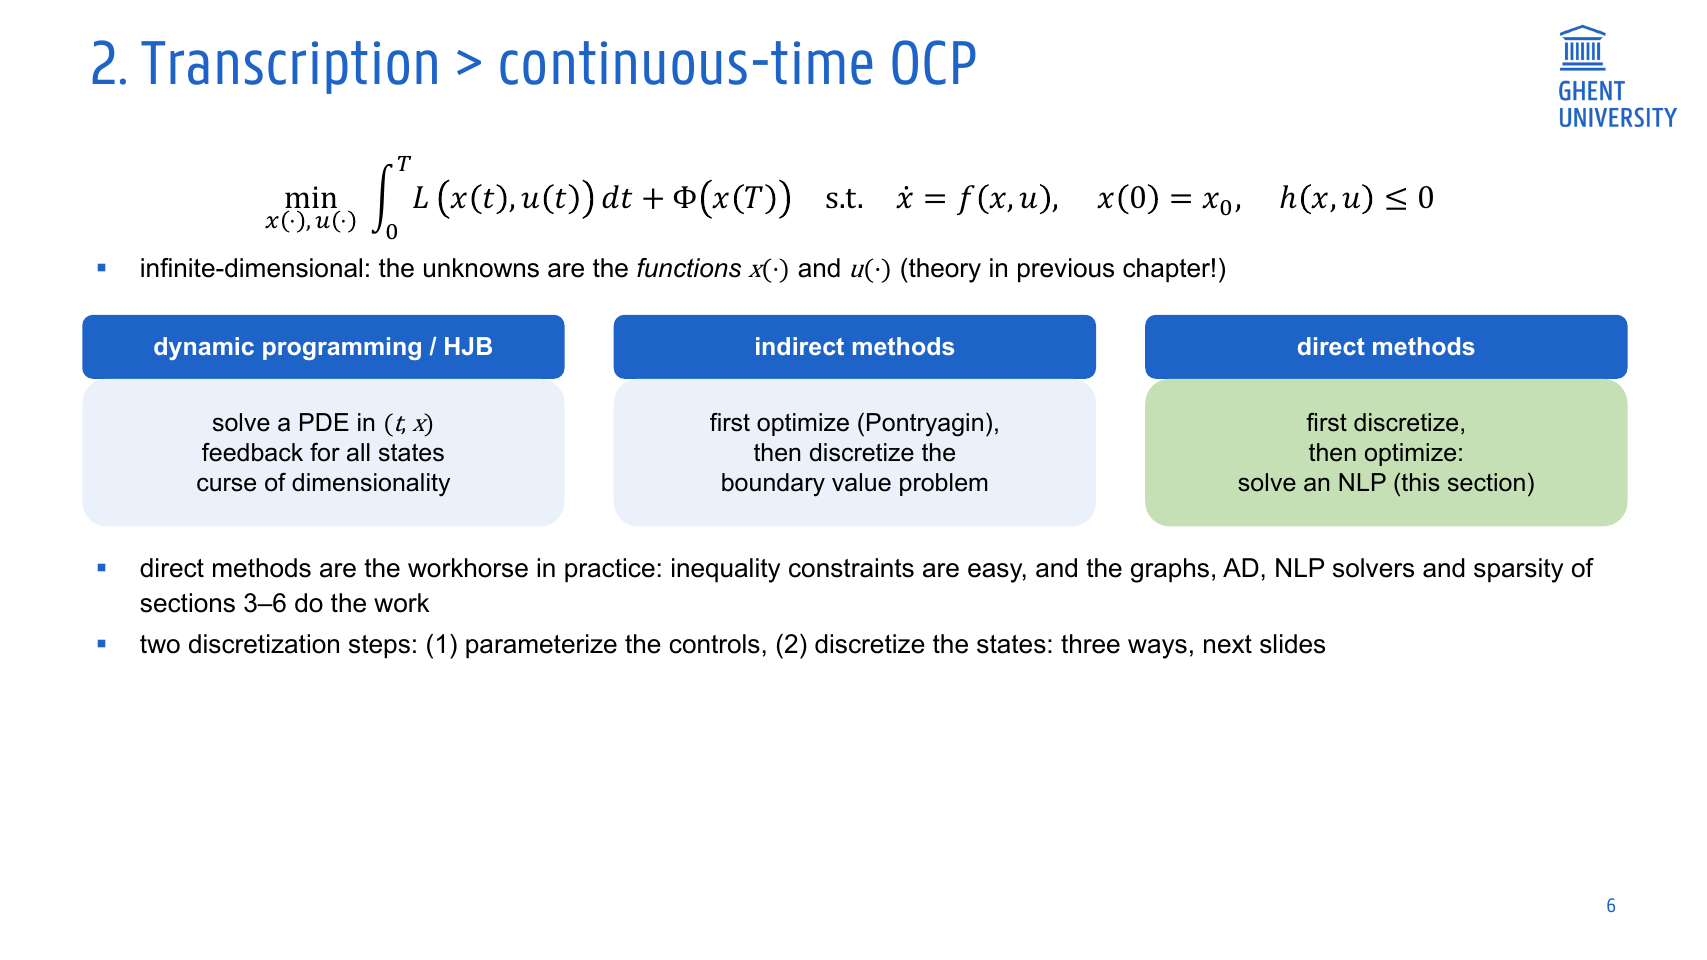

<sub><i>Chapter 5, slide 6: the three families of solution methods. This session is about the direct methods.

### 1.1 Objectives

| Section | Topic | Lecture |
|---|---|---|
| 2 | Introduction to CasADi: solving an NLP, and the graphs, Functions and AD it needs | Ch. 5.3, 5.4, 5.5, 5.7 (notes)|
| 3 | The OCP and its transcription: the integrator $F(s_k,q_k)$ and cost $l_k(s_k,q_k)$ | Ch. 5.2 |
| 4 | Direct single shooting (DSS) | Ch. 5.2, 5.6 |
| 5 | Direct multiple shooting (DMS) and sparsity | Ch. 5.2, 5.5, 5.6 |
| 6 | Take-aways | |
| 7 | **Graded homework**: a three-point turn in a narrow street | Ch. 4 + Ch. 5 |


## 2. Introduction to CasADi: solving an NLP

**Goal of this section.** Every direct method of Chapter 5 ends with the same job: hand a **nonlinear program** (NLP) to a solver. In the notation of the lectures (Ch. 5 slide 7):

$$
\min_{w\in\mathbb{R}^n}\ f(w) \qquad \text{s.t.} \qquad g(w) = 0, \qquad h(w) \le 0,
$$

with decision variables $w$, objective $f(w)$, equality constraints $g$ and inequality constraints $h$. In this section we solve one small NLP with CasADi, and introduce CasADi's ingredients one at a time, exactly when we need them. Our target problem, with $w = (x_1, x_2)$:

$$
\begin{aligned}
\min_{x_1,x_2}\ & 3(1-x_1)^2 e^{-x_1^2-(x_2+1)^2} - 10\left(\tfrac{x_1}{5} - x_1^3 - x_2^5\right)e^{-x_1^2-x_2^2} - \tfrac13 e^{-(x_1+1)^2-x_2^2}\\
\text{s.t.}\ & x_1^2 + x_2^2 - 4 = 0, \qquad x_1, x_2 \in [-3, 3].
\end{aligned}
$$


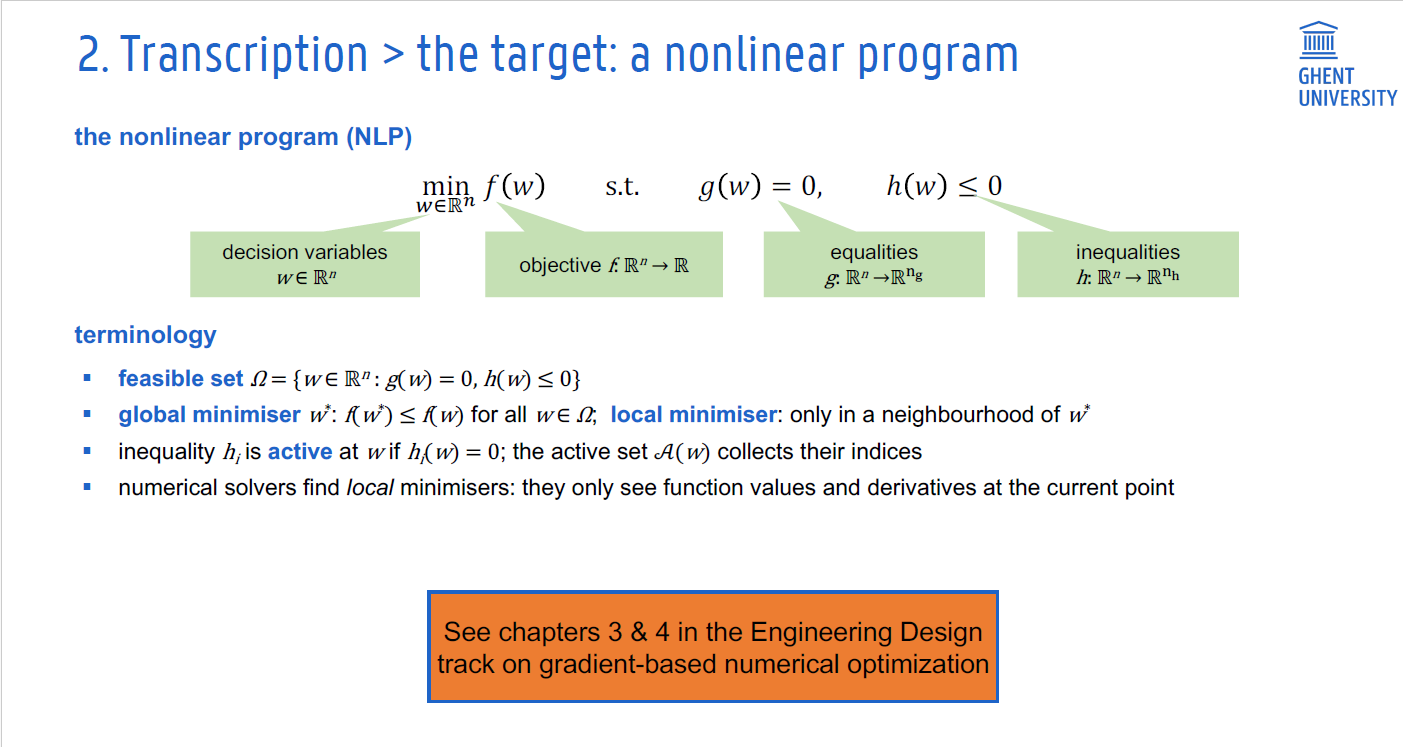

<sub><i>Chapter 5, slide 7: the nonlinear program (NLP) that every direct method produces. This section solves one with CasADi.

**Sections 3 to 5 show how the OCP is reformulated as an NLP, following the approach presented in Slides 8–11**

CasADi (Computer Algebra System for Automatic Differentiation)) is not a modelling language with a fixed problem format but a toolbox to build your own problem. As in Section 5.7 of the lecture notes, every CasADi example consists of **three steps**:

1. **build a symbolic representation** of the problem (a computational graph), Section 2.1;
2. **create a solver instance**, for which **AD** generates the derivative functions the solver needs, Sections 2.2 and 2.3;
3. **evaluate the solver numerically** with bounds and an initial guess, Section 2.4.

For installation, docs, examples, etc. see https://web.casadi.org


In [ ]:
# Install the CasADi package:
!pip install casadi

In [2]:
# Import required packages

import casadi as ca
from casadi import SX, MX
from casadi.tools import dotdraw
import numpy as np
import matplotlib.pyplot as plt
import time, os
np.set_printoptions(precision=4, suppress=True, linewidth=120)

### 2.1 Step 1: symbolic expressions and computational graphs

A symbolic expression is an abstract representation of a formula. Instead of being evaluated right away, it builds a **computational graph** that describes how the outputs depend on the inputs (notes, Section 5.3).

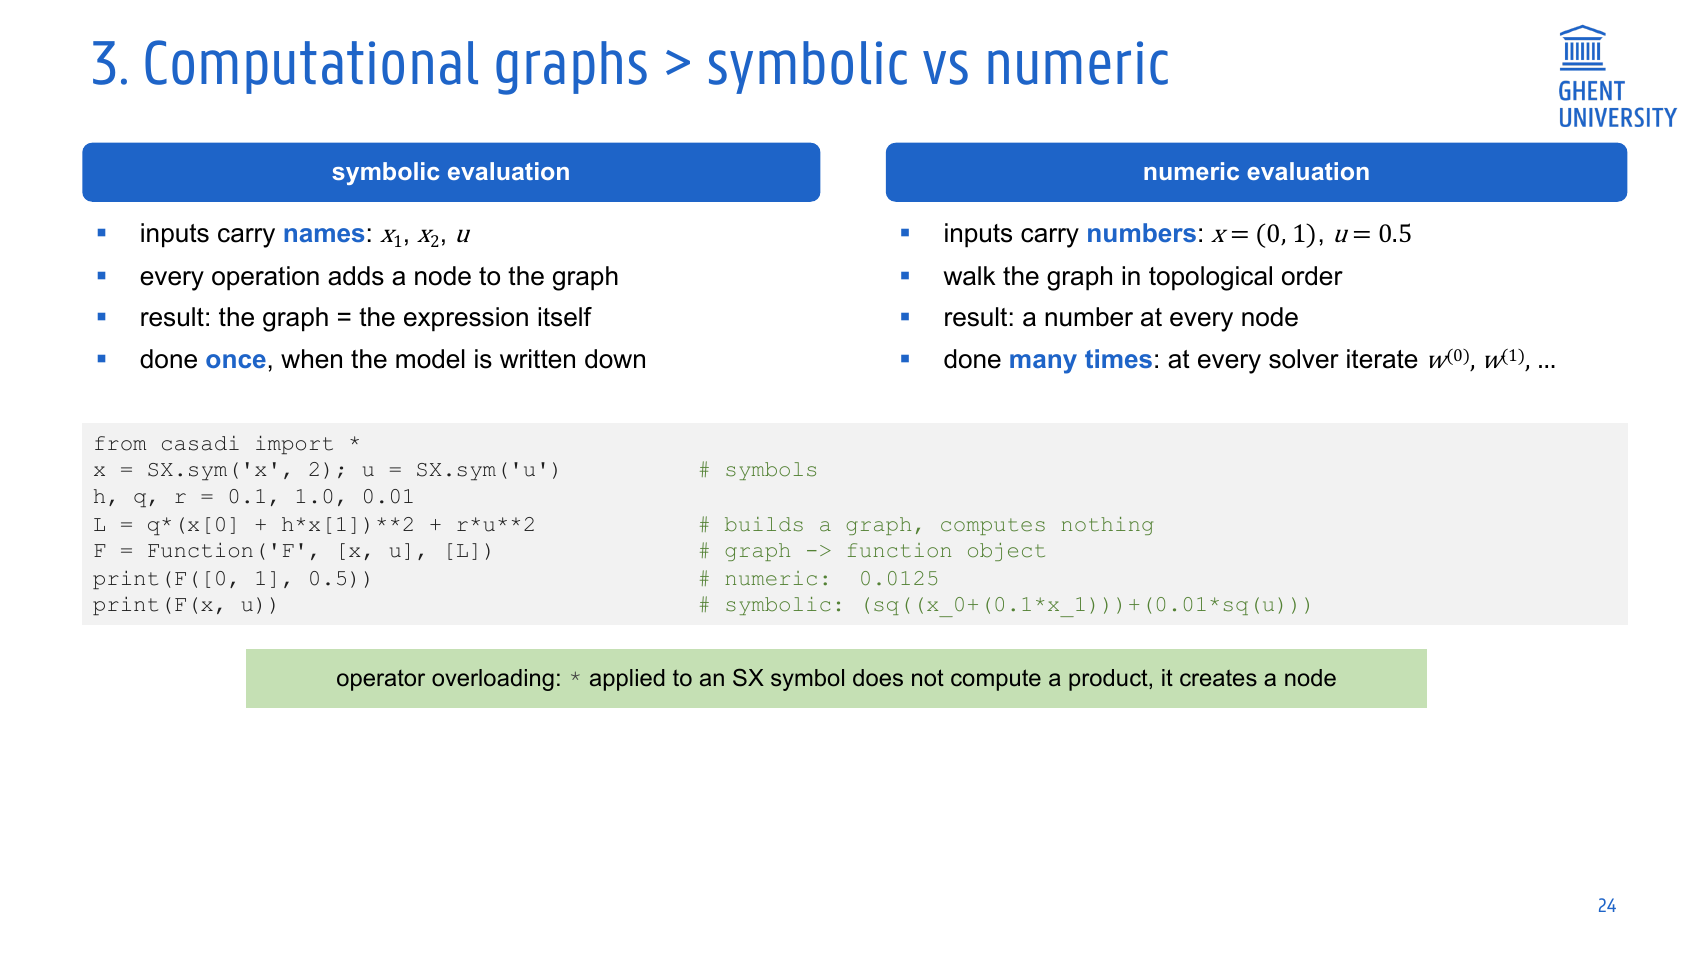

<sub><i>Chapter 5, slide 24: symbolic vs numeric evaluation</i></sub>

CasADi has two graph types: **`SX`** (one node per scalar operation; fast, ideal for small model functions such as our objective) and **`MX`** (one node per matrix operation; can contain calls to other Functions, used later to assemble an NLP around integrator calls).

> Commonly used constructors: `SX.sym(name, n, m)` ($n\times m$ symbolic primitive), `SX.zeros(n, m)`, `SX.eye(n)` (same for `MX`).
>
> Indexing follows **NumPy syntax** (`w[0]`, `w[1]`); standard arithmetic operations work as expected (`+`, `*`, `@`, `.T`, `**`, `ca.sin`, `ca.exp`, ...). Concatenation: `ca.vertcat(a, b)` and `ca.horzcat(a, b)`.

---

**Task 1:** Create the decision variable $w = (x_1, x_2)$ as a $2\times1$ `SX` symbol and build the objective $f(w)$ and the equality constraint $g(w) = x_1^2+x_2^2-4$ of the target NLP as symbolic expressions. Print them: nothing is computed yet, you see the graph.

In [ ]:
w  = SX.sym('w', 2)       # decision variable w = (x1, x2)
x1, x2 = w[0], w[1]

f_nlp = ...   # TODO: objective f(w)
g_nlp = ...   # TODO: equality constraint g(w)

print('f(w) =', f_nlp)
print('g(w) =', g_nlp)

# Visualise the computational graph
dotdraw(g_nlp)
dotdraw(f_nlp)

### 2.2 Function objects: evaluating the graph

To evaluate a graph numerically, turn it into a **`Function`**. A Function is a callable object that can be evaluated, differentiated and exported as C code.

`F = ca.Function(name, [inputs], [outputs], [input_names], [output_names])`

* `name`: display name (shows up in error messages),
* `inputs` / `outputs`: lists of symbolic inputs and output expressions,
* `input_names` / `output_names` (optional): the optional names let you call the function with keywords, e.g. `F(w=...)`.

A Function after definition can be called **numerically** (with numbers) and **symbolically** (with symbols, which embeds it into a bigger graph). We use this a lot from Section 3 on, when an integrator Function is called inside the NLP.

---

**Task 2:** Create a Function `fg` $:\mathbb{R}^2\to\mathbb{R}\times\mathbb{R}$, $w\mapsto(f(w), g(w))$ (the same `f` and `g` as those in the target NLP) with input name `w` and output names `f`, `g`. Evaluate it at the numerical point $w_0=(-1,-1)$, and once symbolically at a new `SX` symbol.

In [ ]:
fg = ...   # TODO: ca.Function('fg', [w], [...], ['w'], ['f', 'g'])
print(fg)

print('numeric : ', fg(w=[-1, -1]))          # keyword call -> dict
v = SX.sym('v', 2)
print('symbolic:', fg(v)[1])                 # positional call -> list of outputs

fg:(w[2])->(f,g) SXFunction
numeric :  {'f': DM(1.85589), 'g': DM(-2)}
symbolic: ((sq(v_0)+sq(v_1))-4)


### 2.3 Step 2: algorithmic differentiation (AD)


CasADi’s symbolic framework enables the automatic and efficient computation of exact derivatives by traversing the underlying computational graphs. Automatic differentiation (AD) decomposes a function or expression into a sequence of elementary operations and repeatedly applies the chain rule to compute its derivatives to machine precision. A simple illustrative example is provided below:

AD.svg




A numerical NLP solver such as IPOPT needs more than $f$ and $g$: it needs the **gradient** $\nabla f(w)$, the **constraint Jacobian** $\partial g/\partial w$ and the **Hessian of the Lagrangian** $\nabla^2_w \mathcal L(w,\lambda)$ with $\mathcal L = f + \lambda^\top g$. Because the graph consists of elementary operations with known derivatives, CasADi applies the chain rule through the graph and obtains these derivatives **exactly** This is algorithmic differentiation (notes, Section 5.4).

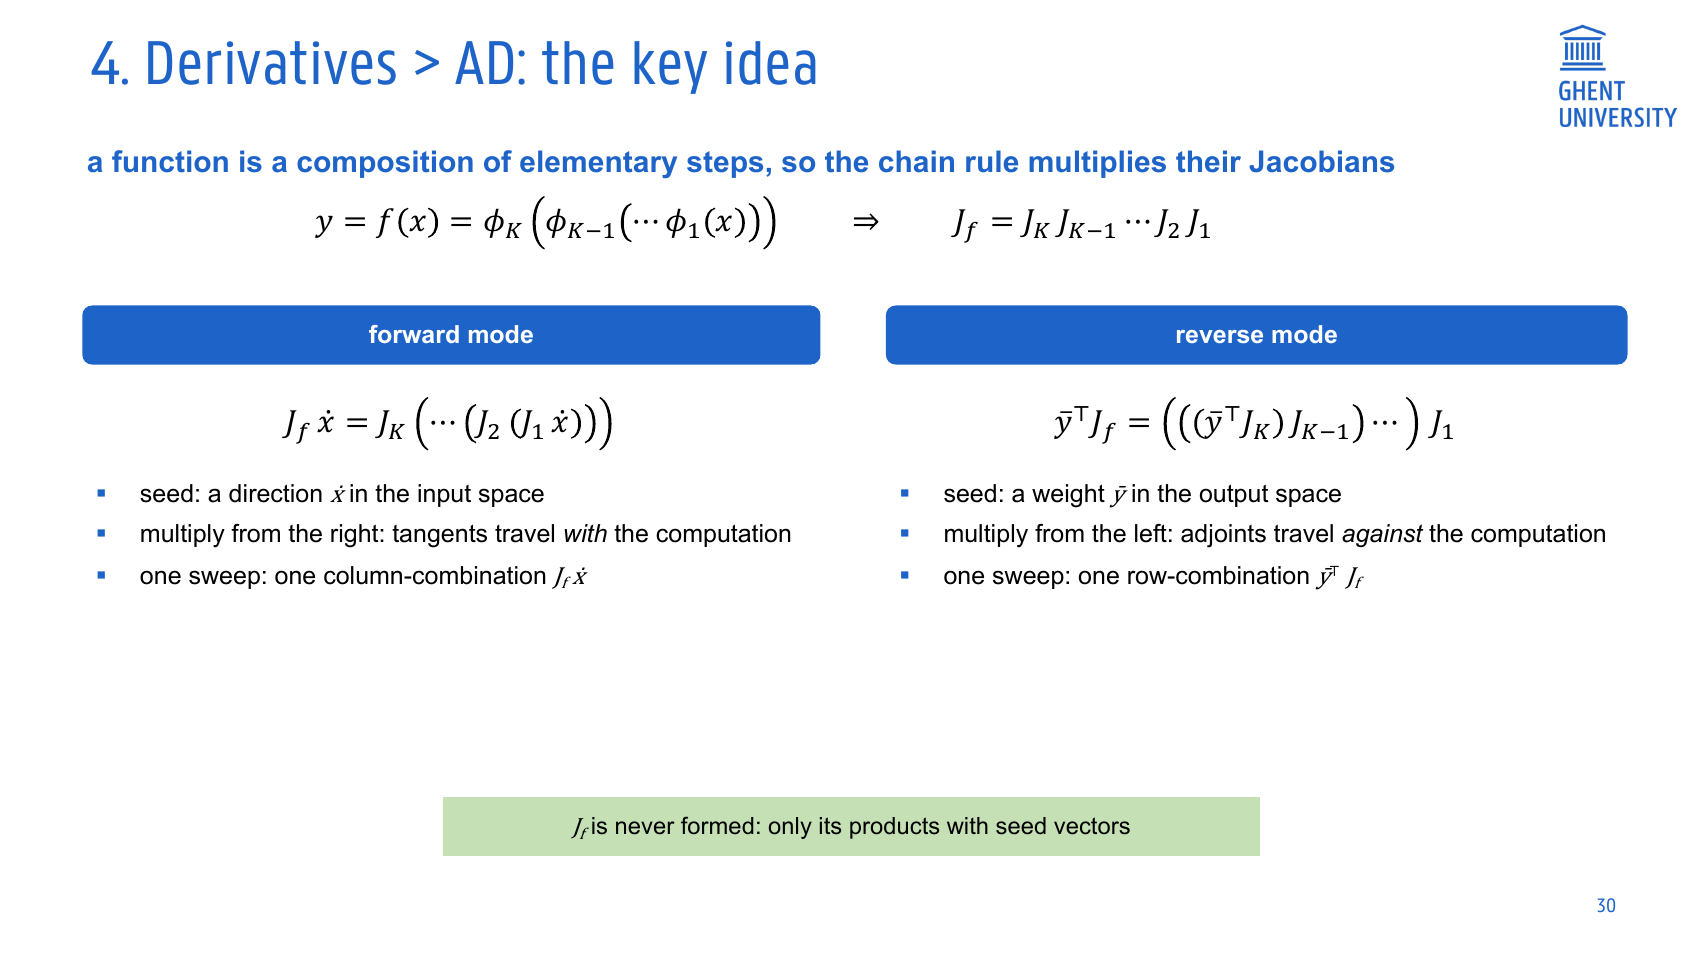

<sub><i>Chapter 5, slide 30: AD applies the chain rule to the elementary operations of the graph</i></sub>

> Gradient of a scalar $f$ w.r.t. $w$: `ca.gradient(f, w)`; Jacobian of a vector expression: `ca.jacobian(g, w)`; Hessian: `H, grad = ca.hessian(f, w)`.

When we create the solver in Section 2.4, it builds exactly these derivative graphs for us. Here we build them by hand once, to see what the solver gets.

---

**Task 3:** Compute $\nabla f(w)$, $\partial g/\partial w$ and the Hessian of the Lagrangian $\nabla^2_w\big(f + \lambda g\big)$ (with a scalar symbol $\lambda$) symbolically. Wrap them in a Function and evaluate it at $w_0 = (-1,-1)$, $\lambda=1$.

In [ ]:
lam = SX.sym('lam')
grad_f = ...   # TODO: gradient of f w.r.t. w
jac_g  = ...   # TODO: Jacobian of g w.r.t. w
hess_L = ...   # TODO: Hessian of f + lam*g w.r.t. w  (ca.hessian returns two outputs)

derivs = ca.Function('derivs', [w, lam], [grad_f, jac_g, hess_L],
                     ['w', 'lam'], ['grad_f', 'jac_g', 'hess_L'])
for name, val in derivs(w=[-1, -1], lam=1).items():
    print(f'{name} =\n{val}')

### 2.4 Steps 2 and 3: create the solver and solve

CasADi's NLP solvers (`nlpsol`) use the form (Compare it with the notation used in the lecture)

$$
\min_{w}\ f(w,p) \quad \text{s.t.}\quad \texttt{lbg} \le g(w,p) \le \texttt{ubg},\qquad \texttt{lbx} \le w \le \texttt{ubx},
$$

so both constraints $g(w)=0$ (use `lbg = ubg = 0`) and $h(w)\le0$ (use `lbg = -inf`, `ubg = 0`) go into CasADi's `g`.

Simple bounds on $w$ go into `lbx`, `ubx`.

$p$ is a fixed parameter (Some parameters can be treated as constants and scheduled in advance).

> ⚠️ **Name clash.** In `nlpsol`, **`x`** is the *decision variable* $w$, **`f`** the *NLP objective* $f(w)$, **`g`** all *constraints*, and **`p`** a *constant parameter*. In the OCP, $x$ is the state and $f$ the dynamics. Keep this in mind from Section 3 on.

| symbol | in the OCP | in `nlpsol` |
|---|---|---|
| `x` | state $x(t)$ | decision variable $w$ |
| `f` | dynamics $f(x,u)$ | objective $f(w)$ |
| `g` and `h` | path constraints | constraints $g(w)=0$ and $h(w)\le0$ |
| `p` | – | constant parameter |

The recipe and syntax:

To solve an NLP with CasADi, start by creating a dictionary containing expressions for `x`, `f`, `g`, and `p`:

```python
nlp    = {'x': w, 'f': f_expr, 'g': g_expr}             # step 1: symbolic problem
```
- `x`: $w$ is an $n \times 1$ symbolic column vector of all decision variables, e.g. `w = SX.sym('w', 2)`.
- `g`: `g_expr` is an $m \times 1$ symbolic column vector of all constraint expressions. A single constraint can be a scalar.
- `f`: `f_expr` must be a symbolic scalar ($1 \times 1$).
- `p`(optional): A symbolic column vector of dimensions $n_p \times 1$.

This symbolic representation of the problem is then used to construct an NLP solver that inherently incorporates automatic differentiation (AD):

```python
solver = ca.nlpsol('solver', 'ipopt', nlp)        # step 2: AD builds gradient, Jacobian, Hessian
```

where the arguments are, respectively, the display name of the solver, the solver plugin here, IPOPT, and the above symbolic problem formulation `nlp`.

There are several NLP solvers interfaced with CasADi. The most popular one is IPOPT (an interior-point method, notes Section 5.5) which is included in CasADi installations.

An NLP solver in CasADi is a function that takes the parameter value `p_value`, the bounds `(lbx, ubx, lbg, ubg)` and a guess for the solution `x0` as inputs. When called, the solver uses these inputs to solve the NLP numerically, as below. It also returns a dictionary containing the optimal solution and a report with information about the optimization process.


```python
sol = solver(x0=w0, lbx=lbw, ubx=ubw, lbg=lbg, ubg=ubg, p=p_value)   # step 3: solve numerically
```
- `lbx`, `ubx`, and `w_0` must have the same size as `w`.
- `lbg` and `ubg` must have the same size as `g`.


When you call the solver, IPOPT prints a log while it optimizes. The log starts with a summary of the NLP (the number of variables, constraints and nonzeros). It then shows one line per iteration with the objective value and the constraint violation. At the end it reports the total number of iterations, the exit status (for example, an optimal solution was found, or the problem is infeasible) and the time the solver took.

`sol` is the dictionary returned by the solver, containing the optimal solution:

```python
sol['x'], sol['f']                     # optimal solution and optimal cost
```
---

**Task 4:**
- Part A: Solve the target NLP from the initial guess $w_0 = (-1, -1)$ with the expressions of Task 1.
- Part B: Print the optimal solution $w^\star$ and $f(w^\star)$. The next cell plots the optimal solution on the objective function's contour plot. Compare it with your own solution. Do they match?
- Part C: Look at the solver’s log and report how many iterations IPOPT needed to find the optimum.
- Part D: Try a few other initial guesses. Do you always land in the same point? Why not?

In [ ]:
# nlp = {...}                                                     # step 1
# solver = ca.nlpsol('solver', 'ipopt', nlp)                      # step 2
# sol = solver(x0=[-1, -1], lbx=..., ubx=..., lbg=..., ubg=...)   # step 3
# print w*, f*
# print('| w* =', sol['x'].full().ravel(), '| f* =', float(sol['f']))

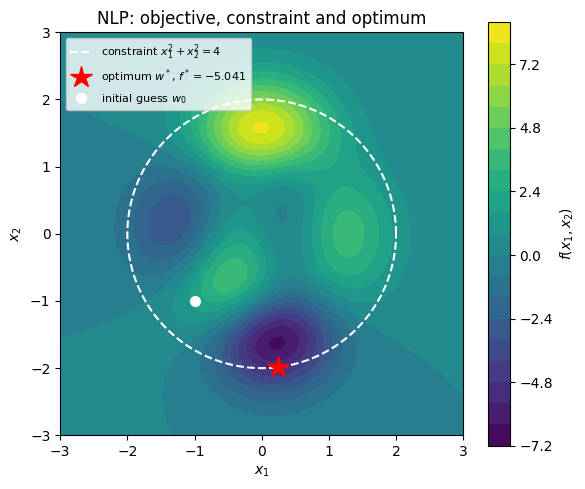

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Objective of the NLP (NumPy version, independent of CasADi)
def f_np(x1, x2):
    return (3*(1 - x1)**2*np.exp(-x1**2 - (x2 + 1)**2)
            - 10*(x1/5 - x1**3 - x2**5)*np.exp(-x1**2 - x2**2)
            - 1/3*np.exp(-(x1 + 1)**2 - x2**2))

# Known optimum (IPOPT from w0 = (-1, -1))
w_star = np.array([0.2465, -1.9848])
f_star = -5.040829256085577

X1, X2 = np.meshgrid(np.linspace(-3, 3, 300), np.linspace(-3, 3, 300))
Z = f_np(X1, X2)

plt.figure(figsize=(6.5, 5.5))
cs = plt.contourf(X1, X2, Z, levels=20, cmap='viridis')
plt.colorbar(cs, label='$f(x_1, x_2)$')
th = np.linspace(0, 2*np.pi, 300)
plt.plot(2*np.cos(th), 2*np.sin(th), 'w--', lw=1.5, label='constraint $x_1^2+x_2^2=4$')
plt.plot(w_star[0], w_star[1], 'r*', ms=16, label=f'optimum $w^*$, $f^*={f_star:.3f}$')
plt.plot(-1, -1, 'wo', ms=7, label='initial guess $w_0$')
plt.xlabel('$x_1$'); plt.ylabel('$x_2$'); plt.title('NLP: objective, constraint and optimum')
plt.gca().set_aspect('equal'); plt.legend(loc='upper left', fontsize=8)
plt.show()

## 3. From OCP to NLP: transcription ingredients

From now on we leave the CasADi basics and transcribe an optimal control problem into an NLP.

### 3.1 Running example: the bicycle model

We use the kinematic model of a wheeled robot (the "bicycle model") driving in the plane:

$$
\dot x = f(x,u) = \begin{bmatrix} v\cos\theta \\ v\sin\theta \\ \omega \end{bmatrix},
\qquad
x = \begin{bmatrix} p_x \\ p_y \\ \theta \end{bmatrix}\in\mathbb{R}^{3},
\qquad
u = \begin{bmatrix} v \\ \omega \end{bmatrix}\in\mathbb{R}^{2},
$$

where $(p_x, p_y)$ is the position, $\theta$ the heading, $v$ the forward speed and $\omega$ the turning rate.

**The OCP.** Steer the robot from $x_s$ to the goal $x_g$ while staying above the floor $p_y\ge 0$ and outside the unit-circle obstacle:

$$
\begin{aligned}
\min_{x(\cdot),\,u(\cdot)}\quad & \int_{0}^{T} \underbrace{(x-x_g)^{\top}Q\,(x-x_g) + u^{\top}R\,u}_{L(x,u)}\,\mathrm{d}t \\
\text{s.t.}\quad & \dot x = f(x,u), \qquad x(0) = x_s, \\
& |v| \le 0.6, \qquad |\omega| \le \tfrac{\pi}{4}, \\
& p_y \ge 0, \qquad p_x^2 + p_y^2 \ge 1 \quad (\text{obstacle}),
\end{aligned}
$$

with $T = 20$, $x_s = (-2, 0, 0)^\top$, $x_g = (1.5, 0.5, 0)^\top$, $Q = \mathrm{diag}(1, 1, 0.1)$ and $R = \mathrm{diag}(0.5, 0.05)$. There is no terminal cost ($\Phi = 0$).

In [ ]:
# ---- Problem data of the running example (Section 3.1) ----
T  = 20.0          # horizon [s]
N  = 100           # number of control intervals
nx, nu = 3, 2      # state and control dimensions n_x, n_u

x_s = np.array([-2.0, 0.0, 0.0])   # start state
x_g = np.array([ 1.5, 0.5, 0.0])   # goal state
Q = np.diag([1.0, 1.0, 0.1])       # state weight
R = np.diag([0.5, 0.05])           # control weight
v_max, omega_max = 0.6, np.pi/4    # input bounds

**Task 5.1:** Create the bicycle model as a CasADi Function **`f`** $:\mathbb{R}^3\times\mathbb{R}^2\to\mathbb{R}^3\times\mathbb{R}$, $(x,u)\mapsto(\dot x, L)$, which returns the ODE right-hand side $f(x,u)$ *and* the running cost $L(x,u)$. Evaluate it numerically at $x = (0, 0, \pi/4)$, $u = (1, 0)$, and symbolically at the symbols `x`, `u`.

> From here on, `x`, `u` and `f` in the code are the **state, control and dynamics of the OCP**.

In [ ]:
x = SX.sym('x', nx)    # x = (p_x, p_y, theta)
u = SX.sym('u', nu)    # u = (v, omega)

xdot = ...                # TODO: ODE right-hand side f(x, u)
L    = ...                # TODO: running cost L(x, u)

f = ...                   # TODO: ca.Function('f', [x, u], [xdot, L], ['x', 'u'], ['xdot', 'L'])

print(f)
print('numeric :', f([0, 0, np.pi/4], [1, 0]))
print('symbolic:', f(x, u)[0])

f:(x[3],u[2])->(xdot[3],L) SXFunction
numeric : (DM([0.707107, 0.707107, 0]), DM(3.06169))
symbolic: [(u_0*cos(x_2)), (u_0*sin(x_2)), u_1]


### 3.2 Discretization ingredients


Every direct method needs two ingredients to transcribe an OCP into an NLP:

1. **Control parameterization**: on a grid $t_k = k h$ with interval length $h = T/N$, the input is piecewise constant, $u(t) = q_k$ for $t\in[t_k,t_{k+1})$, $k = 0,\dots,N-1$.
2. **An integrator on each interval**: starting from the state $s_k$ at $t_k$, $M$ RK4 steps of size $\Delta t = h/M$ give the one-interval map $F(s_k,q_k)\approx x(t_{k+1})$ and, by integrating $L$ along (quadrature), the interval cost $l_k(s_k,q_k)\approx\int_{t_k}^{t_{k+1}}L\,\mathrm{d}t$.

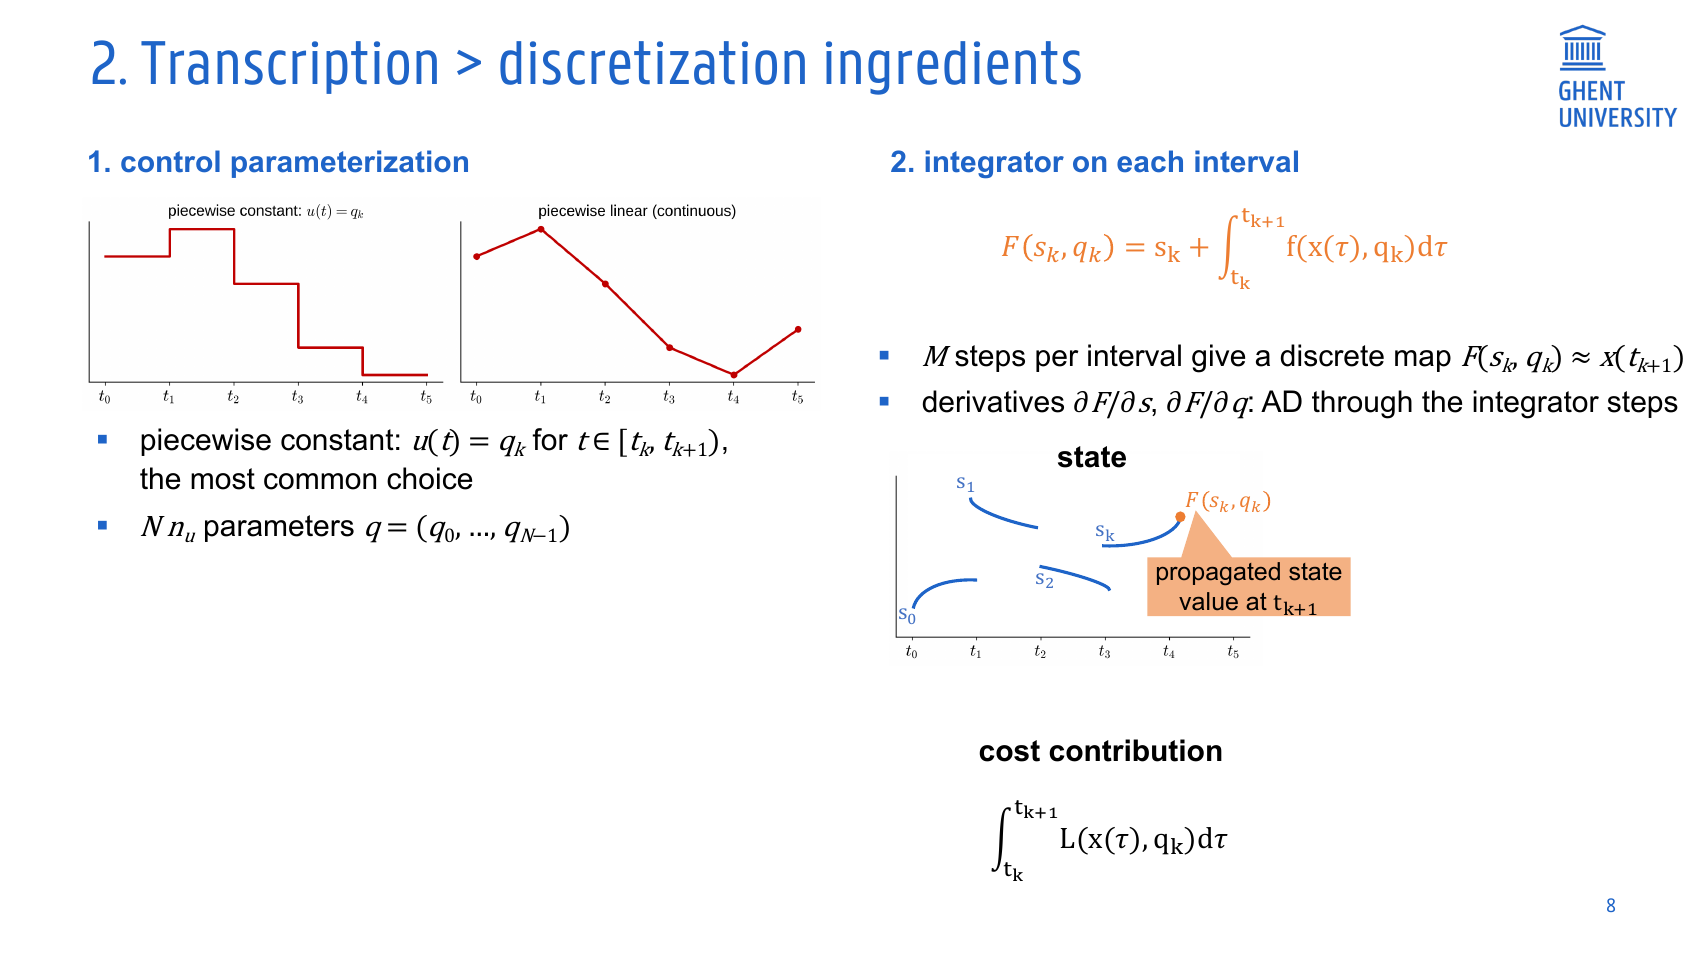

<sub><i>Chapter 5, slide 8: control parameterization and an integrator on each interval </i></sub>



The key rows of a common discretization method:

**RK4 (slide 9)**:

$k_1 = f(x,q),\ k_2 = f(x+\tfrac{\Delta t}{2}k_1,q),\ k_3 = f(x+\tfrac{\Delta t}{2}k_2,q),\ k_4 = f(x+\Delta t\,k_3,q),\ x^+ = x+\tfrac{\Delta t}{6}(k_1+2k_2+2k_3+k_4)$,

and the same for the cost:
 $k^l_1 = l(x,q),\ k^l_2 = l(x+\tfrac{\Delta t}{2}k_1,q),\ k^l_3 = l(x+\tfrac{\Delta t}{2}k_2,q),\ k^l_4 = l(x+\Delta t\,k_3,q),\ L^+ = L + \tfrac{\Delta t}{6}(k^l_1+2k^l_2+2k^l_3+k^l_4)$

Combining both, we can define the function `F`, which takes the current state and input as arguments and integrates the system dynamics and cost over the sampling interval, returning the updated state and the corresponding accumulated cost.

| symbol | meaning | in the code |
|-----|---|---|
| $t_k$, $h$ | grid points, interval length | `h = T/N` |
| $M$, $\Delta t$ | integrator steps per interval, step size | `M`, `dt= h/M` |


---

**Task 5.2:** Evaluate the function `F` at $s_k=(0.2, 0.3, 0.02)$, $q_k=(0.4, 0)$.

In [ ]:
# One-interval map F(s_k, q_k) -> (x(t_{k+1}), l_k) with M fixed steps of size dt = h/M.

h  = T / N
M  = 4
dt = h / M

s = ca.MX.sym('s', nx)
q = ca.MX.sym('q', nu)

X, lk = s, 0                      # start of the interval, zero cost

for j in range(M):
    k1, k1_l = f(X, q)
    k2, k2_l = f(X + dt/2*k1, q)
    k3, k3_l = f(X + dt/2*k2, q)
    k4, k4_l = f(X + dt*k3, q)
    X  = X  + dt/6*(k1   + 2*k2   + 2*k3   + k4)      # advance the state
    lk = lk + dt/6*(k1_l + 2*k2_l + 2*k3_l + k4_l)    # accumulate the cost

F = ca.Function('F', [s, q], [X, lk], ['sk', 'qk'], ['s_next', 'lk'])


# Evaluate the function `F` at $s_k=(0.2, 0.3, 0.02)$, $q_k=(0.4, 0)$:
# print()

### 3.3 Sequential vs simultaneous

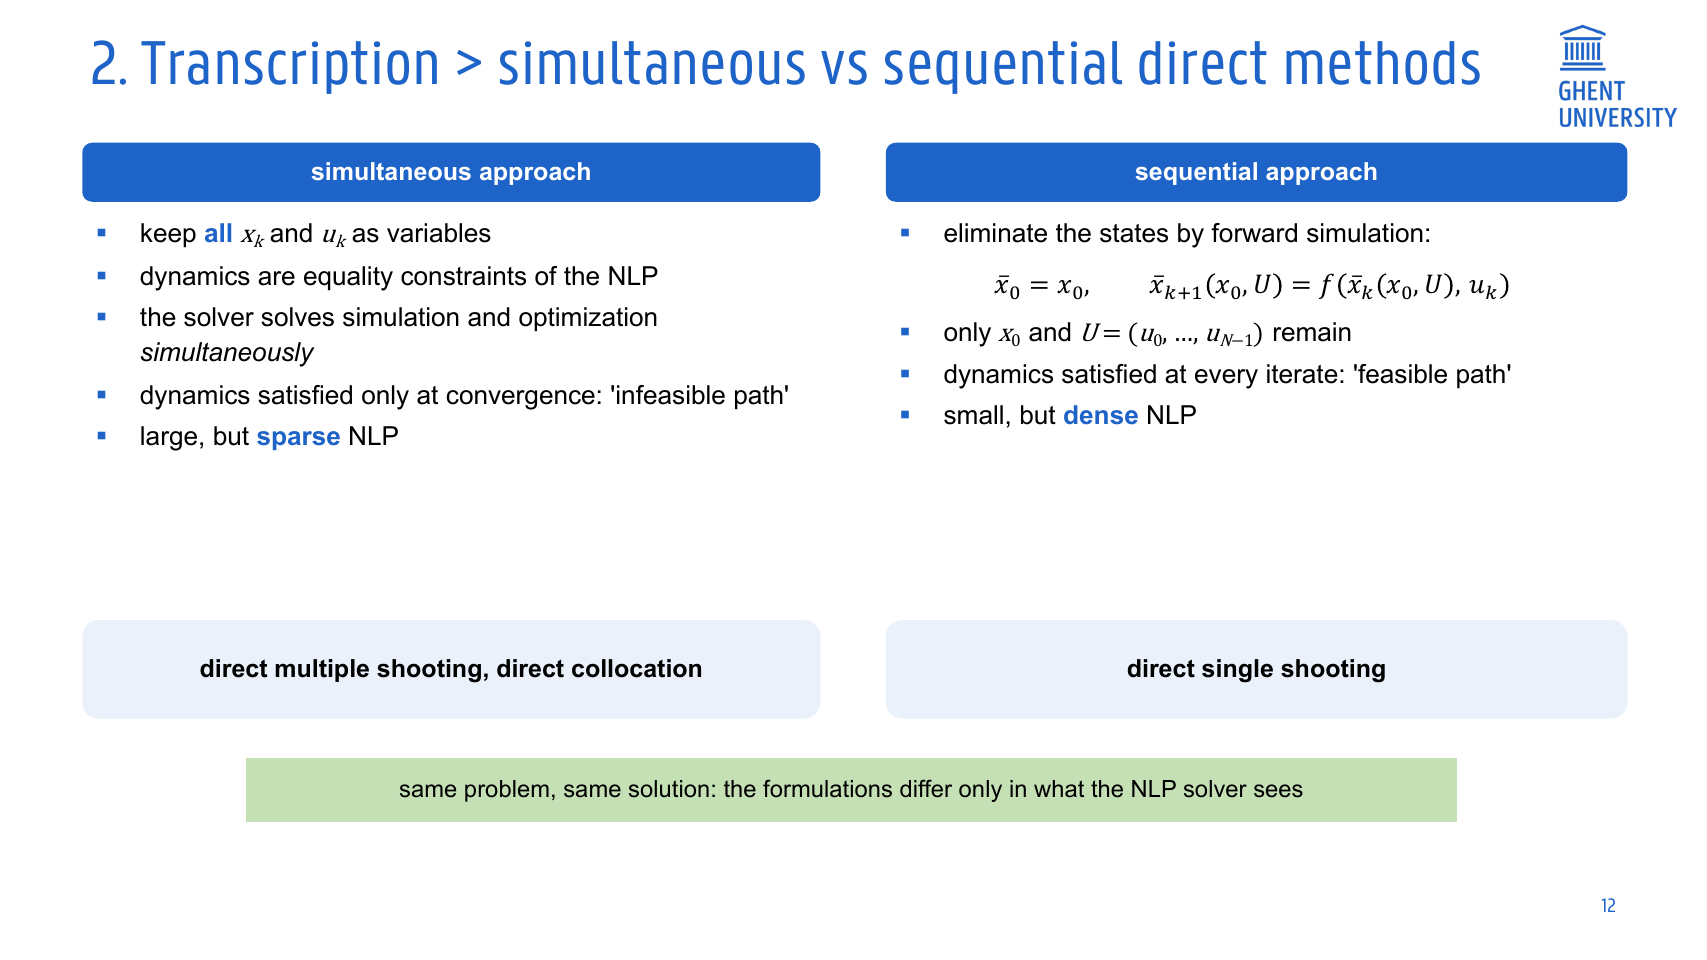

<sub><i>Chapter 5, slide 12: same problem, two ways to hand the dynamics to the NLP solver</i></sub>



* **Sequential (DSS):** eliminate the states by forward simulation, $\bar x_0 = x_s$, $\bar x_{k+1} = F(\bar x_k, q_k)$. Only $w = (q_0,\dots,q_{N-1})$ remain. Small, dense NLP.
* **Simultaneous (DMS, collocation):** keep the states as variables, and the dynamics become equality constraints. Large, sparse NLP.

## 4. Direct single shooting (DSS)

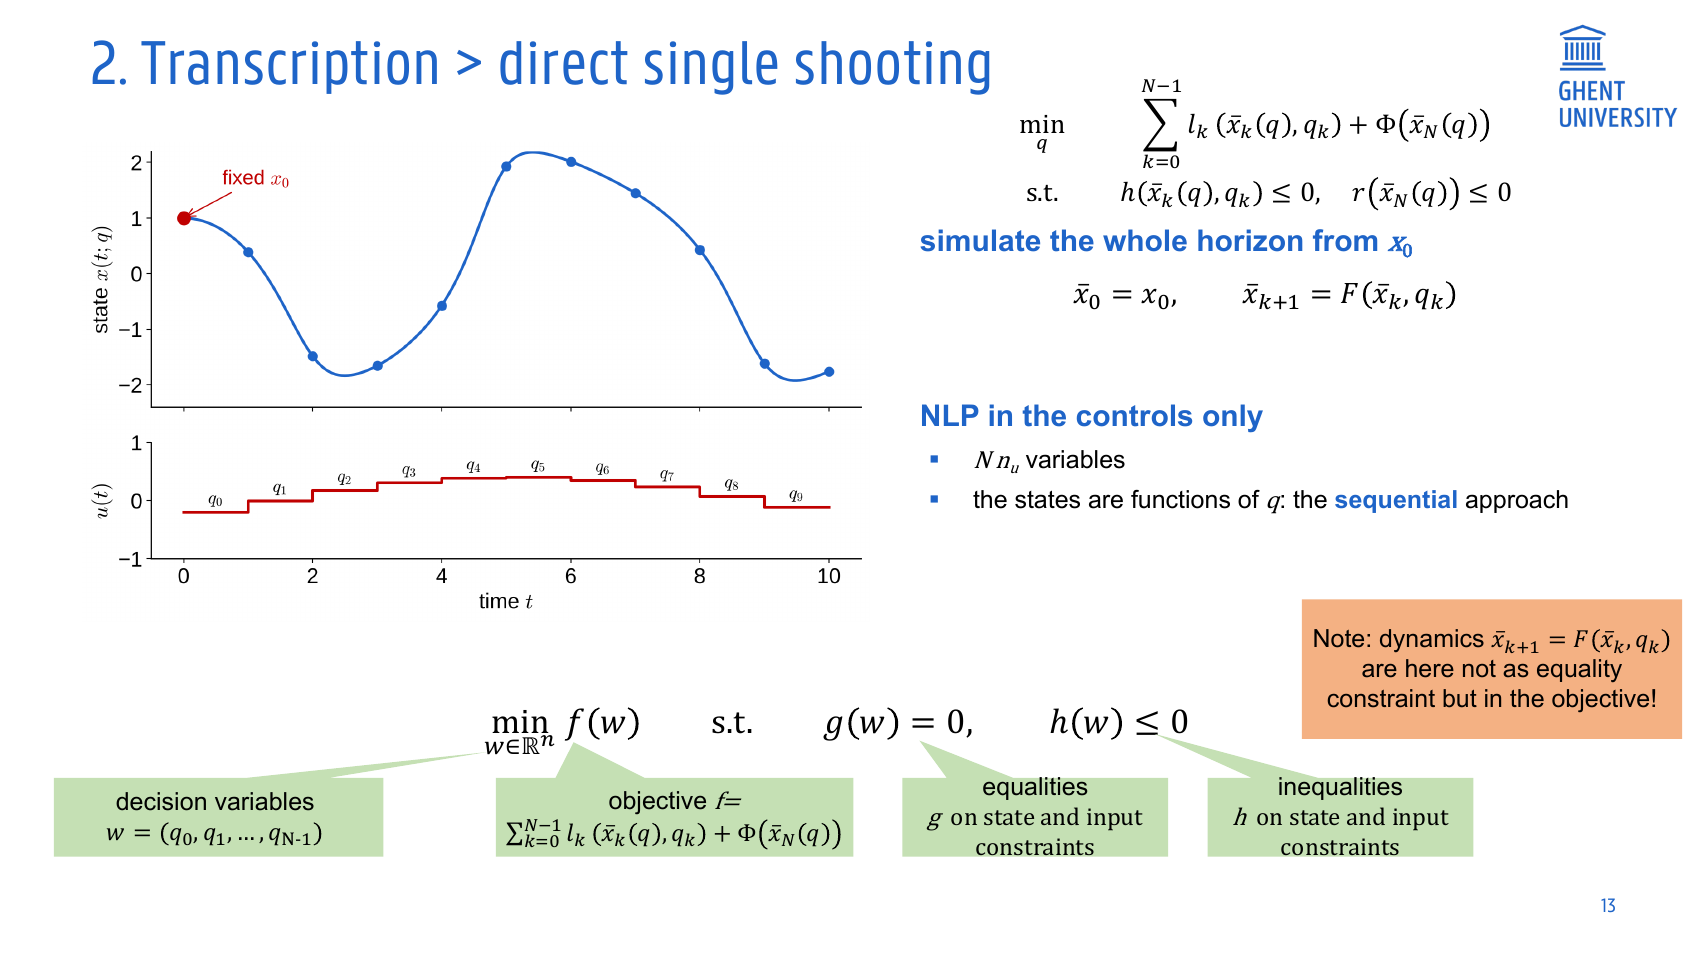

<sub><i>Chapter 5, slide 13: direct single shooting</i></sub>



For the bicycle the DSS NLP reads

$$
\begin{aligned}
\min_{w=(q_0,\dots,q_{N-1})}\quad & \sum_{k=0}^{N-1} l_k\big(\bar x_k(q), q_k\big) \\
\text{s.t.}\quad & -\bar u \le q_k \le \bar u, \qquad \bar p_{y,k+1}(q) \ge 0, \qquad \bar p_{x,k+1}^2(q)+\bar p_{y,k+1}^2(q) \ge 1, \qquad k=0,\dots,N-1,
\end{aligned}
$$

where $\bar x_0 = x_s$, $\bar x_{k+1} = F(\bar x_k, q_k)$. Note that the states are not variables. The input bounds are simple bounds on $w$.

The key lines of the loop:

```python

# Start from initial state to construct the computational graph
Xk = ca.MX(x_s)                      # x̄_0 = x_s (a constant, not a variable)


for k in range(N):

    # Define control input parameters $u_{k}$  as symbolic variables qk.
    qk = ca.MX.sym(f'q_{k}', nu);

    # Construct the NLP decision variables and their bounds and initial guesses by stacking them into lists. (Start with an empty list)
    w += [qk]; lbw += ...; ubw += ...; w0 += ...

    # Obtain each $s_{k+1}$ and compute the cumulative cost in terms of $q_{k}$ and $s_{k}$ using the defined discrete-time function from previous section.
    Fk = F(sk=Xk, qk=qk)

    # Continue to construct the computational graph between symbolic variables of time intervals.
    Xk = Fk['s_next']      

    # Compute the cumulative cost             
    J  = J + Fk['lk']

    # Define the constraints using symbolic expressions in terms of $q_{k}$ and $s_{k}$. Also, define the lower and upper bounds for each constraint.  
    g += [...]; lbg += [...]; ubg += [...]


#Create the resulting NLP in the same manner as described in the previous section.
nlp = {'x': ca.vertcat(*w), 'f': J, 'g': ca.vertcat(*g)}
```

(Section 5.7.6 of the lecture notes shows the same loop for the Van der Pol oscillator.)

---

**Task 6.1:** Complete `build_dss(N)` using above pseudocode, which returns the NLP dictionary and the bounds/initial guess. Initial guess: $q_k = 0$.

In [ ]:
def build_dss(N):
    w, lbw, ubw, w0 = [], [], [], []
    g, lbg, ubg = [], [], []
    J = 0
    Xk = ca.MX(x_s)
    for k in range(N):
        # TODO: new control variable q_k with bounds and initial guess
        # TODO: integrate over the interval, continue the simulation, add the interval cost
        # TODO: floor and obstacle constraints on the new state (general constraints g)
        pass
    args = dict(x0=w0, lbx=lbw, ubx=ubw, lbg=lbg, ubg=ubg)
    return nlp, args, F

**Task 6.2:** Solve the DSS NLP with $N=100$ using the helper `solve_nlp` (given). Reconstruct the state trajectory by simulating the optimal controls and plot it with `plot_xy` (given).

In [ ]:
def solve_nlp(nlp, args, label='', print_level=0):
    # Given helper: solve, time and summarize an NLP.
    S = ca.nlpsol('S', 'ipopt', nlp, {'ipopt.print_level': print_level, 'print_time': False})
    t0 = time.perf_counter()
    sol = S(**args)
    wall = time.perf_counter() - t0
    st = S.stats()
    info = dict(method=label, status=st['return_status'], iters=st['iter_count'],
                cost=float(sol['f']), n_w=nlp['x'].numel(), n_g=nlp['g'].numel(),
                nnz_jac=S.get_function('nlp_jac_g').sparsity_out(1).nnz(),
                nnz_hess=S.get_function('nlp_hess_l').sparsity_out(0).nnz(),   # upper triangle
                time_s=round(wall, 3))
    print(info)
    return sol, info, S

def plot_xy(trajs, title='Bicycle trajectory'):
    # Given helper: plot one or more (label, states, style) trajectories with obstacle, start and goal.
    fig, ax = plt.subplots(figsize=(7, 4))
    th = np.linspace(0, 2*np.pi, 200)
    ax.fill(np.cos(th), np.sin(th), color='r', alpha=0.3, label='obstacle')
    ax.axhline(0, color='k', lw=0.8)
    for lab, X, sty in trajs:
        ax.plot(X[:, 0], X[:, 1], sty, lw=2, label=lab)
    ax.plot(*x_s[:2], 'go', ms=9, label='start $x_s$')
    ax.plot(*x_g[:2], 'ks', ms=9, label='goal $x_g$')
    ax.set_aspect('equal'); ax.grid(True); ax.legend(loc='lower right', fontsize=8)
    ax.set_xlabel('$p_x$'); ax.set_ylabel('$p_y$'); ax.set_title(title)
    return ax

In [ ]:
N = 100
nlp_dss, args_dss, F = build_dss(N)
sol_dss, info_dss, S_dss = solve_nlp(nlp_dss, args_dss, 'DSS')

{'method': 'DSS', 'status': 'Solve_Succeeded', 'iters': 69, 'cost': 28.85232572046809, 'n_w': 200, 'n_g': 200, 'nnz_jac': 20200, 'nnz_hess': 20100, 'time_s': 16.956}


In [ ]:
q_dss = ...   # TODO: reshape the solution into an N x nu array
x_dss = ...   # TODO: simulate the optimal controls from x_s

## 5. Direct multiple shooting (DMS)

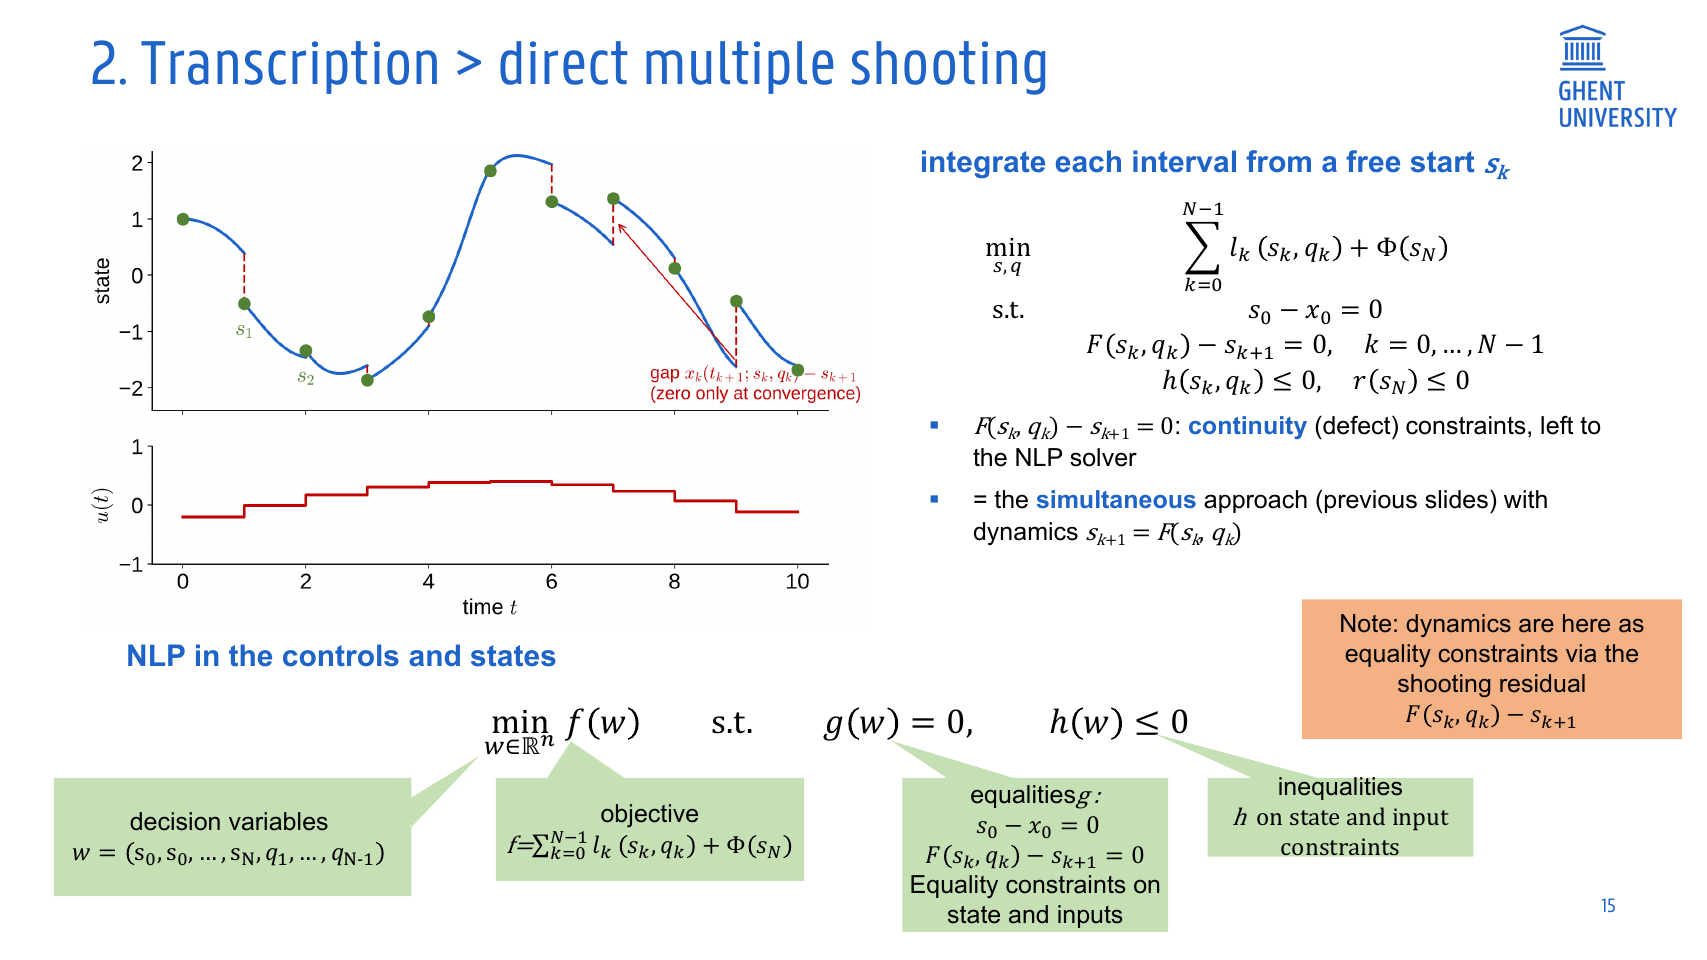

<sub><i>Chapter 5, slide 15: direct multiple shooting </i></sub>



DMS keeps the shooting nodes $s_k$ as optimization variables.

Each interval is integrated from its own free start, and continuity (defect) constraints glue the pieces together:

$$
\begin{aligned}
\min_{w=(s_0,q_0,s_1,q_1,\dots,q_{N-1},s_N)}\quad & \sum_{k=0}^{N-1} l_k(s_k,q_k) \\
\text{s.t.}\quad & s_0 - x_s = 0, \qquad F(s_k,q_k) - s_{k+1} = 0, \qquad k=0,\dots,N-1,\\
& -\bar u \le q_k \le \bar u, \qquad p_{y}(s_{k+1}) \ge 0, \qquad p_x^2(s_{k+1})+p_y^2(s_{k+1}) \ge 1 .
\end{aligned}
$$

**Continuity Constraint:**
We treat the states as optimization variables, meaning that the optimizer will determine their values directly. However, since the state trajectory must be continuous, we enforce this by introducing continuity constraints.

In the above image, each green dot is an optimization variables $s_k$.  
The continuity constraints can be written using the discrete-time dynamics obtained in the previous section as follows:
$$
F(s_k,q_k) - s_{k+1}
$$
Where $s_{k+1}$, $s_k$ and $q_k$ are optimization variables.   
This equation tells us that the end of each blue line, should be the same value as the next green dot.

Implementation notes:
* Order $w$ **stage by stage** ($s_0, q_0, s_1, q_1, \dots$).
* $s_0 = x_s$ can be imposed by setting `lbw = ubw = x_s` for $s_0$.
* State bounds like $p_y\ge 0$ are now **simple bounds** on $w$; only the obstacle stays in $g$.
* The continuity constraints are equalities so for them we have: `lbg = ubg = 0`.

---

**Task 7.1:** Complete `build_dms(N)` like `build_dss(N)` in the previous section using the above implementation notes.

`state_guess` is an $(N+1)\times n_x$ array used to initialize the $s_k$ (default: zeros). Keep the constraint order per stage: 3 continuity rows, then 1 obstacle row.

In [ ]:
def build_dms(N):
    state_guess = np.zeros((N+1, nx))
    w, lbw, ubw, w0 = [], [], [], []
    g, lbg, ubg = [], [], []
    J = 0
    sk = ca.MX.sym('s_0', nx)
    w += [sk]; lbw += list(x_s); ubw += list(x_s); w0 += list(x_s)       # s_0 = x_s
    for k in range(N):
        # TODO: control q_k (bounds, guess)
        # TODO: integrate from s_k, add the interval cost
        # TODO: new node s_{k+1} (bounds: p_y >= 0, guess from state_guess)
        # TODO: continuity constraint F(s_k, q_k) - s_{k+1} = 0   (3 rows)
        # TODO: obstacle constraint on s_{k+1}                     (1 row)
        pass
    nlp = {'x': ca.vertcat(*w), 'f': J, 'g': ca.vertcat(*g)}
    args = dict(x0=w0, lbx=lbw, ubx=ubw, lbg=lbg, ubg=ubg)
    return nlp, args, F

def unpack_dms(wopt, N):
    # Given helper: split w = (s_0, q_0, s_1, ..., q_{N-1}, s_N) into s (N+1 x nx) and q (N x nu).
    wopt = np.asarray(wopt).ravel()
    s = np.array([wopt[k*(nx+nu): k*(nx+nu)+nx] for k in range(N+1)])
    q = np.array([wopt[k*(nx+nu)+nx: (k+1)*(nx+nu)] for k in range(N)])
    return s, q

**Task 7.2:** Solve the DMS NLP with $N=100$ and plot DSS and DMS together. Plot the controls $q_k$ of both methods over time.

In [ ]:
N = 100

# TODO: build DMS using "build_dms" and solve it using "solve_nlp" and unpack the solution using "unpack_dms"

plot_xy([('DSS', x_dss, 'b-'), ('DMS', s_dms, 'g--')], 'DSS vs DMS, N = 100')
plt.show()

tq = np.arange(N)*T/N
fig, ax = plt.subplots(1, 2, figsize=(11, 3))
for i, name in enumerate(['$v$', r'$\omega$']):
    ax[i].step(tq, q_dss[:, i], 'b-', where='post', label='DSS')
    ax[i].step(tq, q_dms[:, i], 'g--', where='post', label='DMS')
    ax[i].set_title(name); ax[i].set_xlabel('t [s]'); ax[i].grid(True); ax[i].legend()
plt.tight_layout(); plt.show()

**Task 7.3 (structure):** Compare DSS and DMS: number of variables and constraints, IPOPT iterations, nonzeros of the constraint Jacobian and of the Hessian of the Lagrangian, wall time (the `info` dictionaries already contain them). Then rebuild both NLPs with $N=10$ and plot the sparsity patterns of $\partial g/\partial w$ and $\nabla^2_w\mathcal L$ with `plt.spy`. Compare with the slide below and explain the difference.

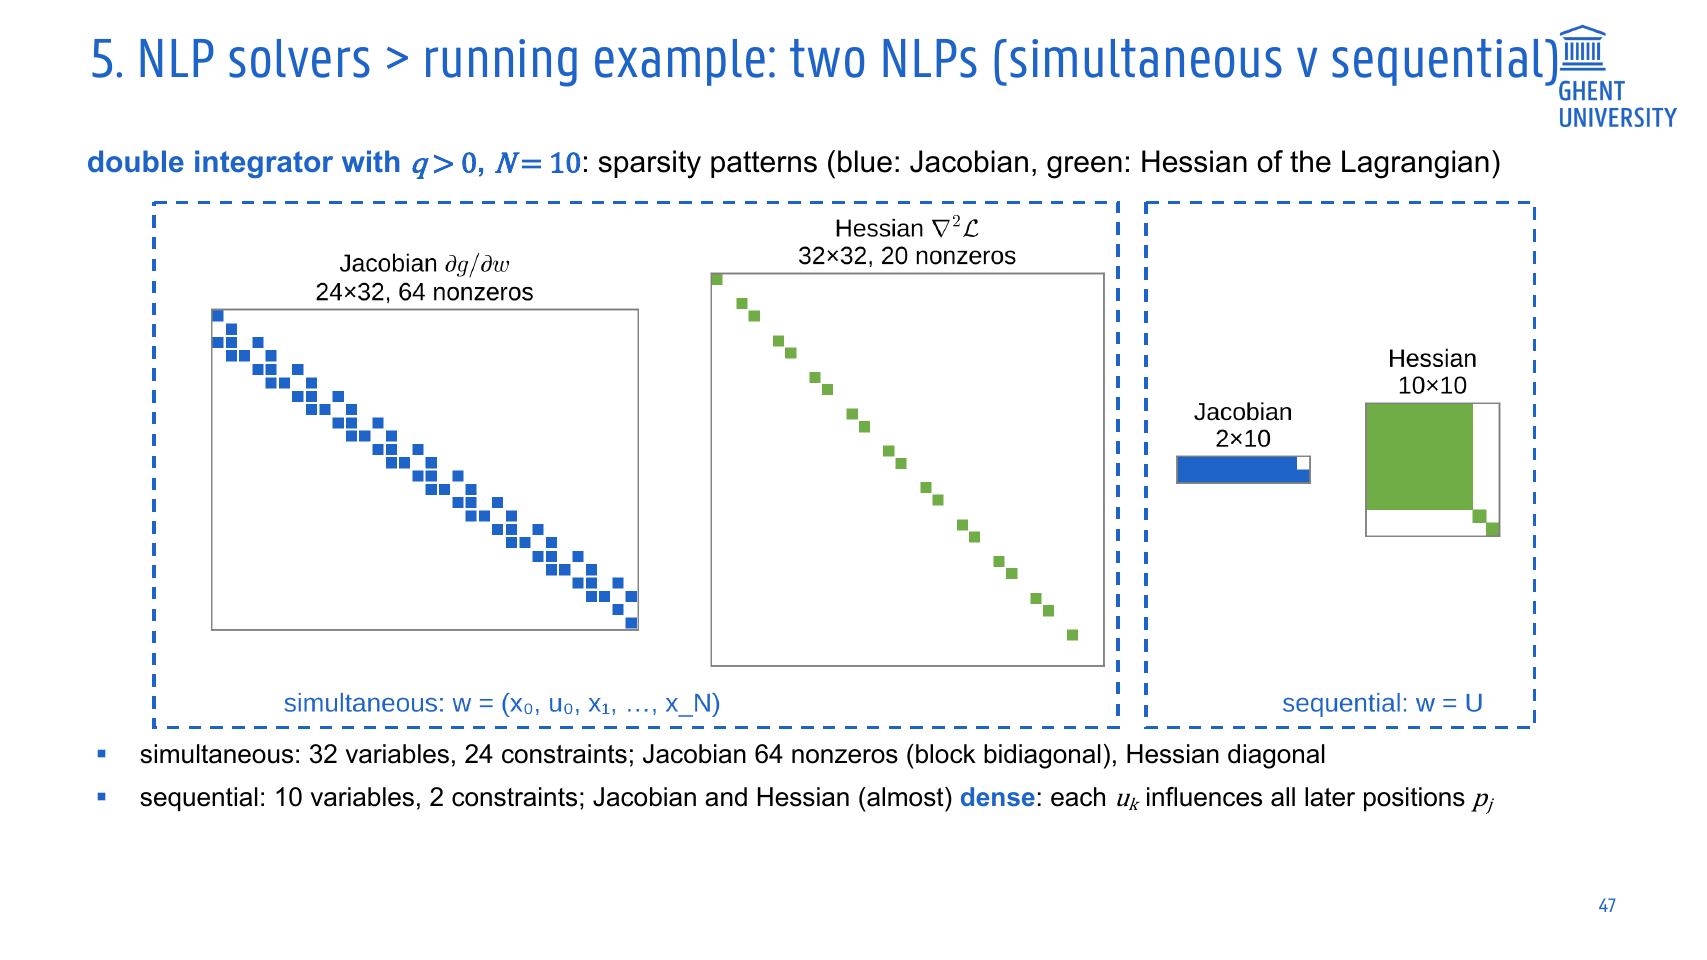

<sub><i>Chapter 5, slide 45: sparsity of the two NLPs for the double integrator </i></sub>

In [ ]:
# It only requires the completed "build_dss" and "build_dms" functions. Nothing to do.

N = 100
nlp_dss, args_dss, F = build_dss(N)
sol_dss, info_dss, S_dss = solve_nlp(nlp_dss, args_dss, 'DSS')
nlp_dms, args_dms, F = build_dms(N)
sol_dms, info_dms, S_dms = solve_nlp(nlp_dms, args_dms, 'DMS')

import pandas as pd
display(pd.DataFrame([info_dss, info_dms]).set_index('method'))

def sparsity_patterns(nlp):
    w_, g_ = nlp['x'], nlp['g']
    lam = ca.MX.sym('lam', g_.numel())
    Jg = ca.jacobian(g_, w_).sparsity()
    Hl = ca.hessian(nlp['f'] + ca.dot(lam, g_), w_)[0].sparsity()
    return ca.DM.ones(Jg).full(), ca.DM.ones(Hl).full()

fig, ax = plt.subplots(2, 2, figsize=(10, 7))
for j, (name, builder) in enumerate([('DSS', build_dss), ('DMS', build_dms)]):
    Jg, Hl = sparsity_patterns(builder(10)[0])
    ax[0, j].spy(Jg, markersize=3); ax[0, j].set_title(f'{name}: Jacobian of g ({int(Jg.sum())} nnz)')
    ax[1, j].spy(Hl, markersize=3); ax[1, j].set_title(f'{name}: Hessian of Lagrangian ({int(Hl.sum())} nnz)')
plt.tight_layout(); plt.show()

## 6. Take-aways

* Direct methods = **first discretize, then optimize**: parameterize $u$ by $q_k$, integrate with $F(s_k,q_k)$, and hand an NLP to IPOPT.
* CasADi builds **computational graphs**; **AD** on these graphs gives exact derivatives for the solver.
* **DSS** (sequential): small but dense; only controls can be initialized; nonlinearity accumulates over the horizon.
* **DMS** (simultaneous): bigger but sparse (block banded), states can be initialized, more robust.
* More practical tips (scaling, initial guesses, SX vs MX, exact Hessian vs BFGS, code generation, `Opti` vs `nlpsol`) are collected in Section 5.7.8 of the lecture notes.

## 7. Homework: a three-point turn in a narrow street

Real cars cannot turn on the spot. In this homework you replace the robot of this session by a **kinematic bicycle** (a car-like vehicle) and let the optimizer discover, on its own, how to turn around in a street that is too narrow for a U-turn. You then study the effect of the effort weight and relate the result to Chapter 4.

**Model.** State $x = (p_x, p_y, \psi, v, \delta)\in\mathbb R^5$ (position, heading, speed, steering angle), input $u = (a, \varphi)$ (acceleration, steering rate), wheelbase $\ell = 0.5$ m:
$$
\dot p_x = v\cos\psi,\qquad \dot p_y = v\sin\psi,\qquad \dot\psi = \frac{v}{\ell}\tan\delta,\qquad \dot v = a,\qquad \dot\delta = \varphi .
$$

**Task.** Start in the right lane at rest, $x_s = (0, -0.4, 0, 0, 0)$, and end in the left lane facing the other way, at rest with straight wheels, $x_g = (0, 0.4, \pi, 0, 0)$, **as fast as possible**:
$$
\begin{aligned}
\min_{T,\;x(\cdot),\;u(\cdot)}\quad & T + \rho\int_0^T \big(a^2+\varphi^2\big)\,\mathrm dt, \qquad \rho = 0.1\\
\text{s.t.}\quad & \dot x = f(x,u),\quad x(0)=x_s,\quad x(T)=x_g,\\
& |p_y|\le 0.8 \ (\text{street walls}),\quad |v|\le 1,\quad |\delta|\le 0.5,\quad |a|\le 1,\quad |\varphi|\le 1,\quad 1\le T\le 40 .
\end{aligned}
$$

The final time is **free**. Use the time-scaling trick: keep $N$ intervals but make $T$ a decision variable, so that $h = T/N$ is an *expression* in the NLP (your integrator must take $h$ as an input).

| Part | What to deliver | Points |
|---|---|---|
| A | Model and integrator with variable $h$ | 15 |
| B | DMS transcription with free final time; solve with $N=60$ | 40 |
| C | Plots and description of the maneuver | 25 |
| D | Effort weight and the link with Chapter 4 | 20 |
| | **Total** | **100** |

**Part A (15 pts).**
1. Implement $f(x,u)$ as an `SX` Function returning $(\dot x,\ \rho(a^2+\varphi^2))$.
2. Implement an RK4 integrator `F(sk, qk, h)` with $M=4$ steps, where the interval length `h` is a **symbolic input**.

**Part B (40 pts).** Write the DMS transcription with $w = (T, s_0, q_0, s_1, \dots, q_{N-1}, s_N)$, $N=60$, $h=T/N$. Impose $s_0=x_s$ and $s_N=x_g$ by bounds, the walls and the bounds on $v$, $\delta$ by bounds on $s_k$, and continuity constraints $F(s_k,q_k,h)-s_{k+1}=0$ for the dynamics. Initialize $T=8$ and the states on a straight line from $x_s$ to $x_g$. Report the solver status, the iterations and $T^\star$. (Your code of Section 5 and Section 5.7.5 of the lecture notes are good templates.)

**Part C (25 pts).** Plot the path in the street with the heading drawn as arrows every few nodes, and plot $v, \delta, a, \varphi$ versus time. Describe the maneuver in words: how many driving segments are there, forward or reverse, and at which times does $v$ change sign?

**Part D (20 pts): effort weight and the link with Chapter 4.**

1. Solve again for $\rho\in\{1,\ 0.1,\ 0.01\}$ and compare $T^\star$ and the shapes of $a(t)$ and $\varphi(t)$.
2. Explain what happens to $a$ and $\varphi$ as $\rho\to 0$, and relate it to the minimum-time example with bounded inputs in Chapter 4 (Ch. 4 slide 69; notes Section 4.7). In a few sentences: how does the direct method of this homework relate to the indirect approach (Pontryagin) of Chapter 4? *Hint:* look at how the Hamiltonian depends on the inputs when $\rho = 0$.